In [1]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from transformers import (AutoProcessor, AutoModelForZeroShotObjectDetection,
                          SamModel, SamProcessor,
                          AutoImageProcessor, AutoModelForDepthEstimation)

(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

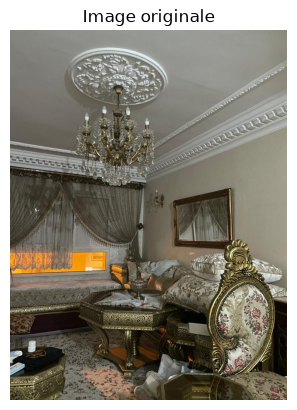

In [2]:
image = Image.open('living_room.jpeg').convert('RGB')
image_np = np.array(image)

plt.imshow(image)
plt.title('Image originale')
plt.axis('off')

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

score : 0.84


(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

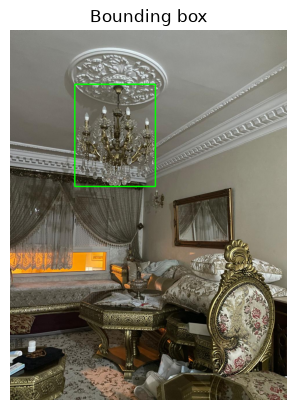

In [3]:
prompt = 'a chandelier.'

processor_dino = AutoProcessor.from_pretrained('IDEA-Research/grounding-dino-tiny')
model_dino = AutoModelForZeroShotObjectDetection.from_pretrained('IDEA-Research/grounding-dino-tiny')

inputs = processor_dino(images=image, text=prompt, return_tensors='pt')
with torch.no_grad():
    outputs = model_dino(**inputs)

results = processor_dino.post_process_grounded_object_detection(
    outputs, inputs.input_ids, threshold=0.3, target_sizes=[image.size[::-1]])[0]

i = results['scores'].argmax()
x1, y1, x2, y2 = [int(v) for v in results['boxes'][i].tolist()]
print('score :', round(results['scores'][i].item(), 2))

image_bbox = image_np.copy()
cv2.rectangle(image_bbox, (x1, y1), (x2, y2), (0, 255, 0), 3)

plt.imshow(image_bbox)
plt.title('Bounding box')
plt.axis('off')

Loading weights:   0%|          | 0/314 [00:00<?, ?it/s]

(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

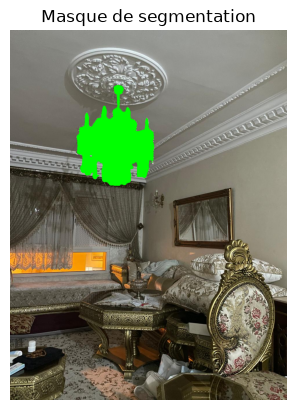

In [4]:
processor_sam = SamProcessor.from_pretrained('facebook/sam-vit-base')
model_sam = SamModel.from_pretrained('facebook/sam-vit-base')

inputs_sam = processor_sam(images=image, input_boxes=[[[x1, y1, x2, y2]]], return_tensors='pt')
with torch.no_grad():
    outputs_sam = model_sam(**inputs_sam)

masks = processor_sam.image_processor.post_process_masks(
    outputs_sam.pred_masks, inputs_sam['original_sizes'], inputs_sam['reshaped_input_sizes'])
mask = masks[0][0][0].numpy()

image_mask = image_np.copy()
image_mask[mask] = [0, 255, 0]

plt.imshow(image_mask)
plt.title('Masque de segmentation')
plt.axis('off')

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

distance camera - objet : 4.76 m


(np.float64(-0.5), np.float64(959.5), np.float64(1279.5), np.float64(-0.5))

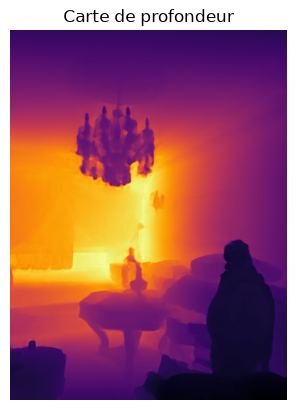

In [5]:
modele = 'depth-anything/Depth-Anything-V2-Metric-Indoor-Small-hf'
processor_depth = AutoImageProcessor.from_pretrained(modele)
model_depth = AutoModelForDepthEstimation.from_pretrained(modele)

with torch.no_grad():
    outputs_depth = model_depth(**processor_depth(images=image, return_tensors='pt'))

depth = torch.nn.functional.interpolate(
    outputs_depth.predicted_depth.unsqueeze(1), size=image_np.shape[:2],
    mode='bicubic', align_corners=False).squeeze().numpy()

print('distance camera - objet :', round(depth[mask].mean(), 2), 'm')

plt.imshow(depth, cmap='inferno')
plt.title('Carte de profondeur')
plt.axis('off')